# Zelle 1: Imports & Indizes laden

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Berechnete Perk-Indizes aus Tag 3 Teil 1 laden
df_indices = pd.read_csv('data/traveltide_user_perk_indices.csv')

print(f"Indizes für {len(df_indices):,} Nutzer geladen.")
df_indices.head()

Indizes für 50,000 Nutzer geladen.


,user_id,meal_index,baggage_index,cancellation_index,bargain_hunter_index,free_night_index
0,55,0.67141,0.97002,0.94416,0.52349,0.44446
1,88,0.93878,0.86556,0.45264,0.38132,0.90277
2,134,0.46166,0.79621,0.45264,0.80586,0.54905
3,207,0.39477,0.84089,0.94416,0.94560,0.25223
4,394,0.93363,0.86556,0.98105,0.91994,0.85866


# Zelle 2: Minimum-Rank-Segmentation durchführen

In [3]:
index_cols = ['meal_index', 'baggage_index', 'cancellation_index', 'bargain_hunter_index', 'free_night_index']

# Mapping von Index-Namen zu den offiziellen Perk-Bezeichnungen von Elena Tarrant
perk_mapping = {
    'meal_index': 'free_hotel_meal',
    'baggage_index': 'free_checked_bag',
    'cancellation_index': 'no_cancellation_fees',
    'bargain_hunter_index': 'exclusive_discounts',
    'free_night_index': '1_night_free_hotel_with_flight'
}

# 1. Absteigendes Ranking (Höchster Wert = Rang 1)
df_ranks = pd.DataFrame({'user_id': df_indices['user_id']})

for col in index_cols:
    # rank(ascending=False) sorgt dafür, dass der beste Score Rang 1 bekommt
    df_ranks[col + '_rank'] = df_indices[col].rank(ascending=False, method='min')

rank_cols = [col + '_rank' for col in index_cols]

# 2. Den besten Rang (Minimum Rank) pro User ermitteln
df_ranks['best_rank_col'] = df_ranks[rank_cols].idxmin(axis=1)

# 3. Den zugewiesenen Perk mappen (Entfernen des '_rank'-Suffixes und Anwenden des Mappings)
df_ranks['assigned_index'] = df_ranks['best_rank_col'].str.replace('_rank', '')
df_ranks['assigned_perk'] = df_ranks['assigned_index'].map(perk_mapping)

# Ergebnis-Übersicht
print("=== Zuweisungs-Ergebnis (Fuzzy / Minimum Rank Segmentation) ===")
perk_counts = df_ranks['assigned_perk'].value_counts()
print(perk_counts)

=== Zuweisungs-Ergebnis (Fuzzy / Minimum Rank Segmentation) ===
assigned_perk
no_cancellation_fees              36892
free_checked_bag                   4025
1_night_free_hotel_with_flight     3652
free_hotel_meal                    2778
exclusive_discounts                2653
Name: count, dtype: int64


# Zelle 3: Visualisierung der Perk-Verteilung

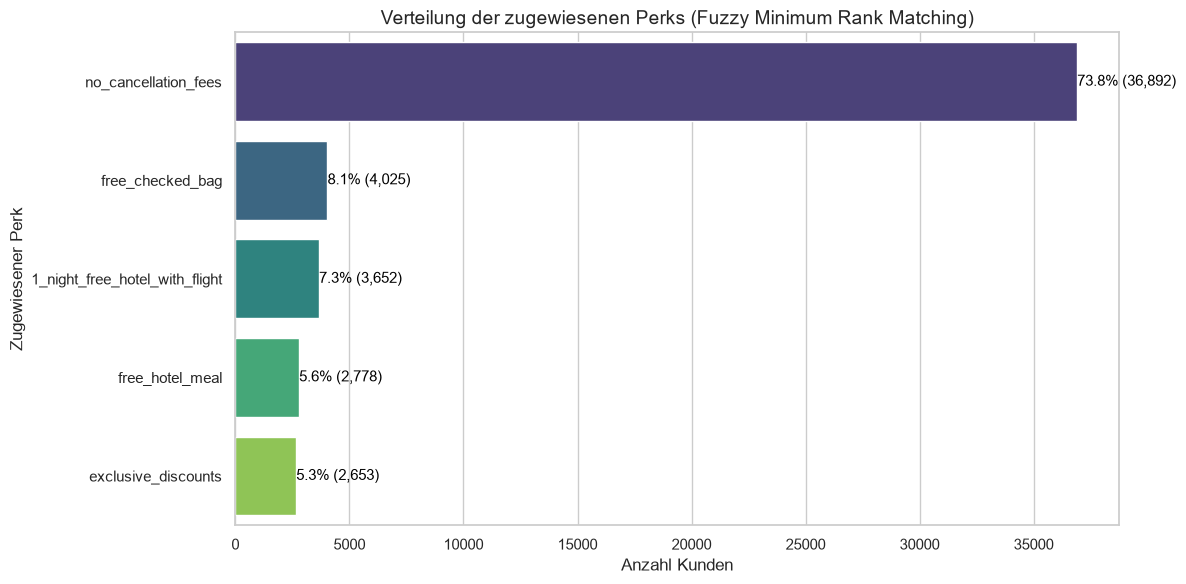

In [7]:
# Balkendiagramm der Perk-Verteilung
plt.figure(figsize=(12, 6))
ax = sns.barplot(x=perk_counts.values, y=perk_counts.index, hue=perk_counts.index, palette="viridis")

plt.title("Verteilung der zugewiesenen Perks (Fuzzy Minimum Rank Matching)", fontsize=14)
plt.xlabel("Anzahl Kunden")
plt.ylabel("Zugewiesener Perk")

# Prozentuale Beschriftung an den Balken
total = len(df_ranks)
for p in ax.patches:
    percentage = f'{100 * p.get_width() / total:.1f}% ({int(p.get_width()):,})'
    ax.annotate(percentage, (p.get_width() + 15, p.get_y() + p.get_height() / 2),
                ha='left', va='center', fontsize=11, color='black')

plt.tight_layout()
plt.show()

 ## Ranking-Glitches bei Ties
 * Das liegt an der Art, wie wir in Pandas die Ränge berechnet haben:
 * Wie wir vorhin gesehn haben, haben  über 90 % der Kunden bei cancellation_index exakt den Wert 0.0 (weil sie nie storniert haben).   
 * Wenn du .rank(ascending=False, method='min') auf eine Spalte anwendest, bei der tausende Kunden denselben Wert 0.0 haben, weist Pandas allen diesen Kunden exakt Rang 1 zu!
 * Weil Rang 1 der kleinstmögliche Rang ist (min_rank = 1), dachte der Algorithmus für jeden Kunden: "Super, bei Storno stehe ich auf Platz 1, also ist das mein bester Perk!
 * "Die Korrektur: **Perzentil-Kompensation** (Relative Indizes vergleichen)Anstatt die absoluten Tabellenränge (1 bis 50.000) zu vergleichen, vergleichen wir direkt die 5 skalierten Indizes (0.0 bis 1.0) und weisen dem Kunden den Perk mit dem höchsten Wert (Maximum Score) zu!

=== Korrigiertes Zuweisungs-Ergebnis ===
assigned_perk
free_checked_bag                  12356
exclusive_discounts               11599
1_night_free_hotel_with_flight     9924
free_hotel_meal                    9343
no_cancellation_fees               6778
Name: count, dtype: int64


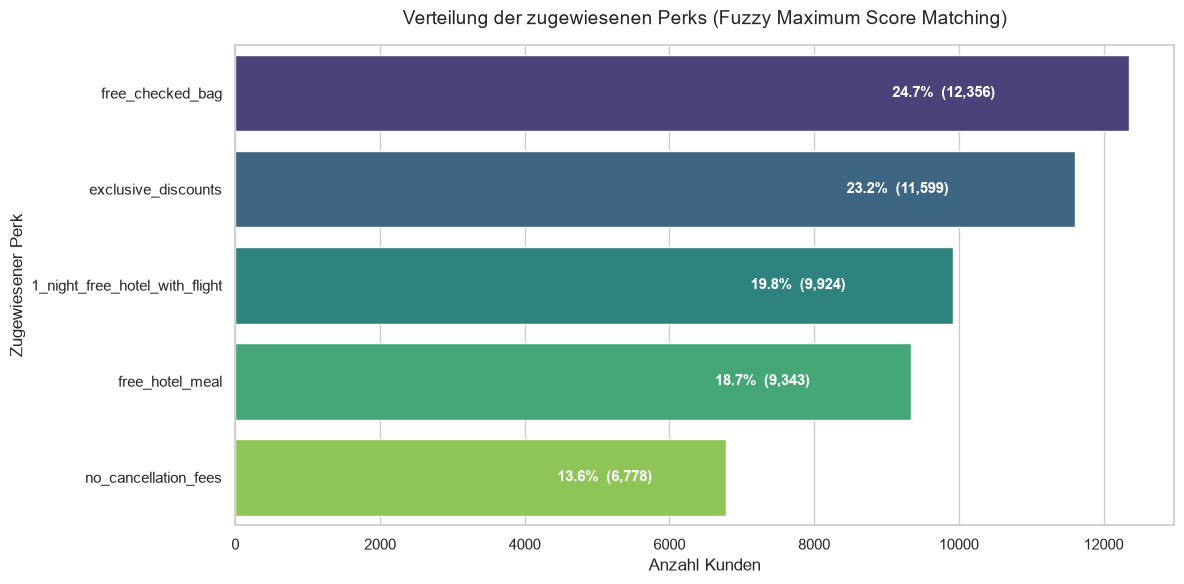

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# 1. Perk-Indizes laden
df_indices = pd.read_csv('data/traveltide_user_perk_indices.csv')

index_cols = ['meal_index', 'baggage_index', 'cancellation_index', 'bargain_hunter_index', 'free_night_index']

perk_mapping = {
    'meal_index': 'free_hotel_meal',
    'baggage_index': 'free_checked_bag',
    'cancellation_index': 'no_cancellation_fees',
    'bargain_hunter_index': 'exclusive_discounts',
    'free_night_index': '1_night_free_hotel_with_flight'
}

# 2. Den höchsten Indexwert (Maximum Score) pro User ermitteln
df_assignments = pd.DataFrame({'user_id': df_indices['user_id']})
df_assignments['best_index_col'] = df_indices[index_cols].idxmax(axis=1)
df_assignments['assigned_perk'] = df_assignments['best_index_col'].map(perk_mapping)

# 3. Zuweisungs-Ergebnis
perk_counts = df_assignments['assigned_perk'].value_counts()
print("=== Korrigiertes Zuweisungs-Ergebnis ===")
print(perk_counts)

# 4. Barplot mit innenliegenden Prozentzahlen
plt.figure(figsize=(12, 6))

# Hue explizit als y übergeben, um Deprecation-Warnings zu vermeiden
ax = sns.barplot(
    x=perk_counts.values, 
    y=perk_counts.index, 
    hue=perk_counts.index, 
    legend=False, 
    palette="viridis"
)

plt.title("Verteilung der zugewiesenen Perks (Fuzzy Maximum Score Matching)", fontsize=14, pad=15)
plt.xlabel("Anzahl Kunden", fontsize=12)
plt.ylabel("Zugewiesener Perk", fontsize=12)

# Beschriftung INNEN in den Balken platzieren
total_users = len(df_assignments)

for p in ax.patches:
    width = p.get_width()
    percentage = (width / total_users) * 100
    
    # Text-Format: e.g., "28.5% (14,250)"
    label_text = f'{percentage:.1f}%  ({int(width):,})'
    
    # x-Position leicht eingerückt innerhalb des Balkens
    x_pos = width * 0.85 if width > total_users * 0.1 else width + 500
    color = 'white' if width > total_users * 0.1 else 'black'
    ha = 'right' if width > total_users * 0.1 else 'left'
    
    ax.annotate(
        label_text, 
        (x_pos, p.get_y() + p.get_height() / 2),
        ha=ha, va='center', 
        fontsize=11, fontweight='bold', 
        color=color
    )

plt.tight_layout()
plt.show()

## Korrigierte Version

=== Zuweisungs-Ergebnis für 50,000 Kunden ===
assigned_perk
free_checked_bag                  12356
exclusive_discounts               11599
1_night_free_hotel_with_flight     9924
free_hotel_meal                    9343
no_cancellation_fees               6778
Name: count, dtype: int64


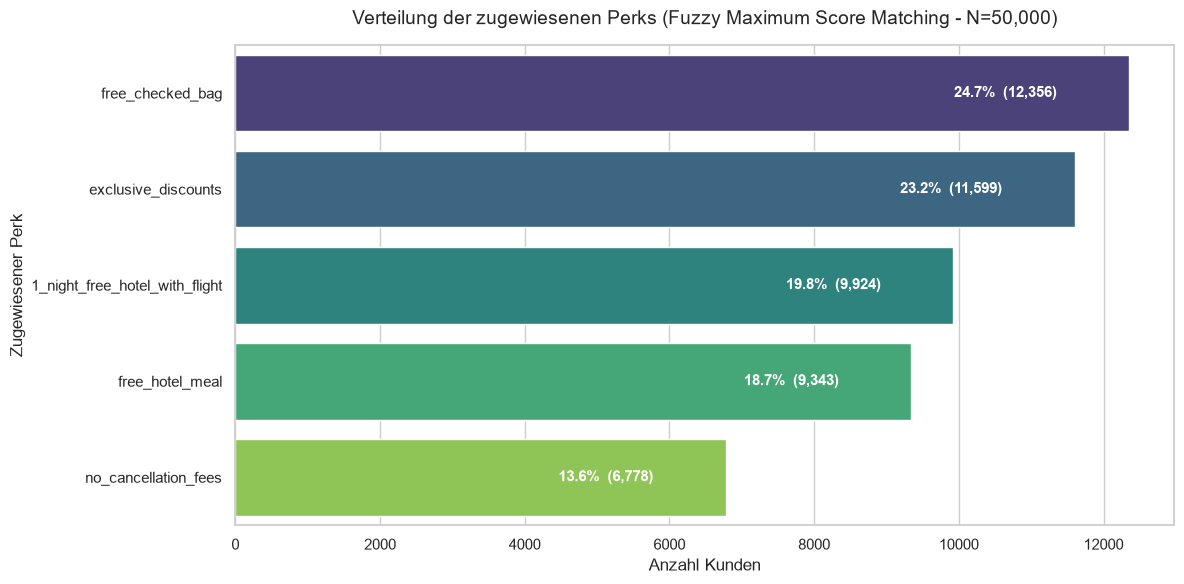


Zuordnungen erfolgreich unter 'data/perk_assignments.csv' gespeichert!


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Perk-Indizes laden
df_indices = pd.read_csv('data/traveltide_user_perk_indices.csv')

index_cols = ['meal_index', 'baggage_index', 'cancellation_index', 'bargain_hunter_index', 'free_night_index']

perk_mapping = {
    'meal_index': 'free_hotel_meal',
    'baggage_index': 'free_checked_bag',
    'cancellation_index': 'no_cancellation_fees',
    'bargain_hunter_index': 'exclusive_discounts',
    'free_night_index': '1_night_free_hotel_with_flight'
}

# 2. Den höchsten Perzentil-Indexwert pro User ermitteln
df_assignments = pd.DataFrame({'user_id': df_indices['user_id']})
df_assignments['best_index_col'] = df_indices[index_cols].idxmax(axis=1)
df_assignments['assigned_perk'] = df_assignments['best_index_col'].map(perk_mapping)

# 3. Ergebnis-Übersicht
perk_counts = df_assignments['assigned_perk'].value_counts()
print(f"=== Zuweisungs-Ergebnis für {len(df_assignments):,} Kunden ===")
print(perk_counts)

# 4. Barplot mit innenliegenden Prozentzahlen & Anzahlen
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=perk_counts.values, 
    y=perk_counts.index, 
    hue=perk_counts.index, 
    legend=False, 
    palette="viridis"
)

plt.title(f"Verteilung der zugewiesenen Perks (Fuzzy Maximum Score Matching - N={len(df_assignments):,})", fontsize=14, pad=15)
plt.xlabel("Anzahl Kunden", fontsize=12)
plt.ylabel("Zugewiesener Perk", fontsize=12)

# Beschriftungen INNEN in den Balken platzieren
total_users = len(df_assignments)

for p in ax.patches:
    width = p.get_width()
    percentage = (width / total_users) * 100
    label_text = f'{percentage:.1f}%  ({int(width):,})'
    
    # Positionierung & Textfarbe je nach Balkenlänge
    if width > total_users * 0.12:
        x_pos = width - (total_users * 0.02)
        color = 'white'
        ha = 'right'
    else:
        x_pos = width + (total_users * 0.01)
        color = 'black'
        ha = 'left'
        
    ax.annotate(
        label_text, 
        (x_pos, p.get_y() + p.get_height() / 2),
        ha=ha, va='center', 
        fontsize=11, fontweight='bold', 
        color=color
    )

plt.tight_layout()
plt.show()

# 5. Export der geforderten CSV-Datei
df_assignments[['user_id', 'assigned_perk']].to_csv('data/perk_assignments.csv', index=False)
print("\nZuordnungen erfolgreich unter 'data/perk_assignments.csv' gespeichert!")